# Paper figures — *Cosmic string GW backgrounds at LISA: II* ([arXiv:2607.15219](https://arxiv.org/abs/2607.15219))

This notebook makes every figure and Table II of the paper with `gwbf_foregrounds`, **from the
saved results in `results/`**, in the layout of the paper. Run it from the `examples/` folder
(or the repository root) after `pip install -e ".[all]"`.

| Paper | Here | Needs |
|---|---|---|
| Table II | §1 | precision summaries, Fisher file, MCMC precision |
| Fig. 2 | §2 | trained posterior (downloaded), dataset at $G\mu=10^{-14}$ |
| Fig. 3 | §3 | precision summaries |
| Fig. 4 | §4 | precision summary, MCMC precision, Fisher file |

**Data used.** SBI precision: the 20-realisation scans of the analysis. MCMC precision: `results/mcmc_precision_paper.npz`. Fisher: Fisher matrix of the likelihood plus the Gaussian foreground priors (`fisher_priors_95_intervals.npz`; classic Fisher without priors in `fisher_95_intervals.npz`).

Expensive inputs can be regenerated in §5 (off by default).

In [1]:
%matplotlib inline
import os, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import gwbf_foregrounds as gf
from gwbf_foregrounds import FULL, NOFG, data, posterior, reconstruct, scan, summary, mcmc
from gwbf_foregrounds.plotting import precision as P
from gwbf_foregrounds.plotting.spectra import plot_reconstruction, plot_noise_and_pls

ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
RES = ROOT / "results"          # saved inputs
OUT = ROOT / "figures"          # figures are written here
OUT.mkdir(exist_ok=True)

# Trained posteriors: None = download from the GitHub release on first use (~230 MB each),
# or a folder containing posterior_full.pkl / posterior_gbexb.pkl / posterior_nofg.pkl
POSTERIOR_DIR = None

def load_post(model):
    m = gf.get_model(model)
    src = os.path.join(POSTERIOR_DIR, m.posterior_file) if POSTERIOR_DIR else m.name
    return posterior.load_posterior(src, m.param_names)

# Fisher used in Table II and Fig. 4:
#   "fisher_priors_95_intervals.npz" = Fisher + Gaussian foreground priors (same information as SBI/MCMC)
#   "fisher_95_intervals.npz"        = classic Fisher (likelihood only)
FISHER_FILE = "fisher_priors_95_intervals.npz"

S = lambda name: RES / name
print("results:", RES, "\nfigures:", OUT)

results: /home/zaldivar/Documents/Androniki/Github2/GWBackFinder-foregrounds/results 
figures: /home/zaldivar/Documents/Androniki/Github2/GWBackFinder-foregrounds/figures


## 1. Table II — reconstruction precision δGμ [%]

δGμ = 100 (Gμ_hi − Gμ_lo)/Gμ_inj for the 95% HDI. SBI: mean over 20 noise realisations.

In [2]:
mc = np.load(S("mcmc_precision_paper.npz"))   # MCMC precision
MCMC = (mc["logGmu_inj"], mc["precision"])
rows = summary.table_ii(S("sbi_fg_summary_with_errors.npz"), S("sbi_nofg_summary_with_errors.npz"),
                        mcmc=MCMC, fisher=S(FISHER_FILE))
print(summary.format_table_ii(rows))

 Gmu_inj |       SBI      MCMC     Fisher | SBI no fg
-----------------------------------------------------
   1e-16 |    725.47    570.12   1.21e+04 |     18.71
   1e-15 |    229.49    200.12     206.09 |      8.56
   1e-14 |     91.47     88.23     103.56 |      6.03
   1e-13 |     46.88     52.11      55.39 |      3.22
   1e-12 |     22.06     22.10      24.54 |      2.30
   1e-11 |     11.36     11.30      11.39 |      1.91
   1e-10 |      7.72      7.26       5.96 |      2.52


In [3]:
# Fisher with priors (used), classic Fisher, and the Fisher column of paper v2
FISHER_PAPER = {-16: 1.85e5, -15: 183.78, -14: 68.73, -13: 41.90, -12: 18.81, -11: 7.99, -10: 4.02}
fp, fc = np.load(S("fisher_priors_95_intervals.npz")), np.load(S("fisher_95_intervals.npz"))
at = lambda d, g: float(d["precision"][np.isclose(d["logGmu_inj"], g)][0])
print(f"{'Gmu':>6} | {'+ priors':>9} {'classic':>9} {'paper v2':>9} | {'SBI':>7}")
for r in rows:
    g = r['logGmu']
    print(f"1e{g:<4} | {at(fp, g):9.4g} {at(fc, g):9.4g} {FISHER_PAPER[g]:9.4g} | {r['sbi']:7.2f}")

   Gmu |  + priors   classic  paper v2 |     SBI
1e-16  | 1.207e+04  1.57e+05  1.85e+05 |  725.47
1e-15  |     206.1     223.6     183.8 |  229.49
1e-14  |     103.6       108     68.73 |   91.47
1e-13  |     55.39      58.9      41.9 |   46.88
1e-12  |     24.54     26.92     18.81 |   22.06
1e-11  |     11.39     13.46      7.99 |   11.36
1e-10  |     5.962     8.283      4.02 |    7.72


In [4]:
print(summary.format_table_ii(rows, latex=True))   # LaTeX version

\begin{tabular}{c|ccc|c}
$G\mu_{\rm inj}$ & SBI & MCMC & Fisher & SBI (no fg) \\ \hline
$10^{-16}$ & 725.47 & 570.12 & 1.21e+04 & 18.71 \\
$10^{-15}$ & 229.49 & 200.12 & 206.09 & 8.56 \\
$10^{-14}$ & 91.47 & 88.23 & 103.56 & 6.03 \\
$10^{-13}$ & 46.88 & 52.11 & 55.39 & 3.22 \\
$10^{-12}$ & 22.06 & 22.10 & 24.54 & 2.30 \\
$10^{-11}$ & 11.36 & 11.30 & 11.39 & 1.91 \\
$10^{-10}$ & 7.72 & 7.26 & 5.96 & 2.52 \\
\end{tabular}


## 2. Fig. 2 — reconstructed spectra at Gμ = 10⁻¹⁴

Posterior median (solid), 95% band, injected (dashed); MBHB fixed; AA noise.

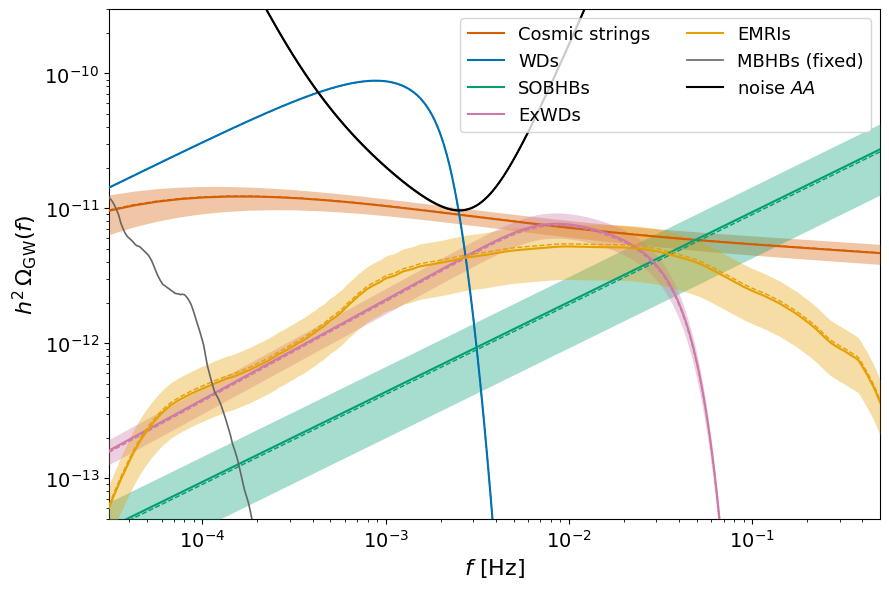

In [5]:
post_full = load_post("full")
ds14 = data.Dataset.load(S("dataset_full_logGmu_m14p0_seed42.npz"))   # Gmu = 1e-14, seed 42
sbi14 = posterior.sample(post_full, ds14, n=10_000, seed=0)
rec14 = reconstruct.reconstruct(sbi14, FULL, ds14.f_obs, truth=ds14.params, max_samples=1000)
fig2 = plot_reconstruction(rec14, show_noise=True, ylim=(5e-14, 3e-10), out=OUT / "fig2_reconstruction.pdf")

## 3. Fig. 3 — precision vs Gμ: foreground budgets (upper) and amplitudes ±1σ (lower)

Error bars: standard deviation over 20 realisations. Red arrows: bars beyond the plot range.

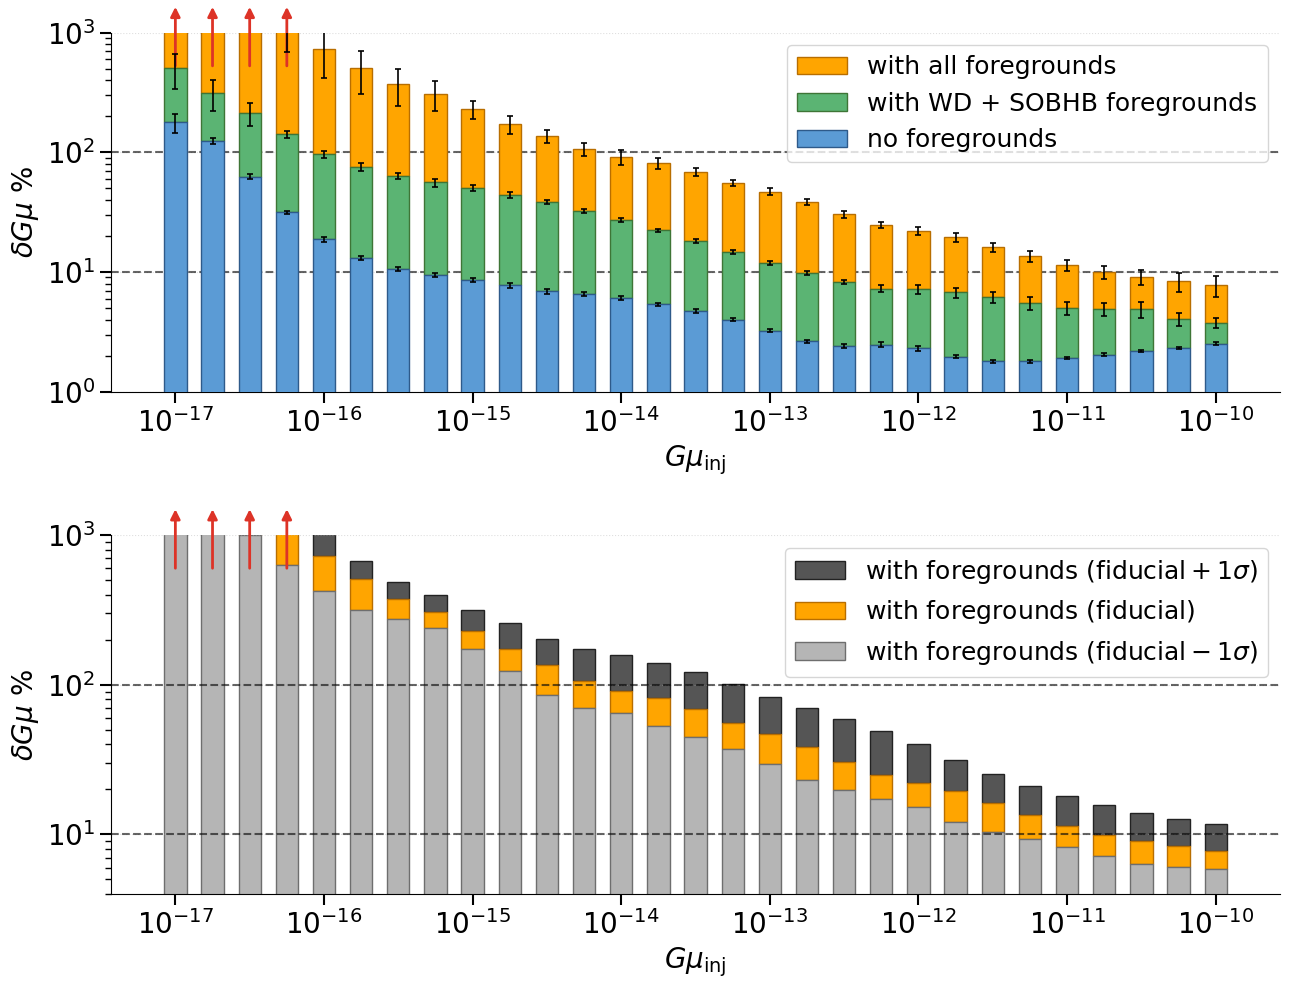

In [6]:
fig3 = P.plot_paper_fig3(S("sbi_nofg_summary_with_errors.npz"), S("sbi_gbexb_summary_with_errors.npz"),
                         S("sbi_fg_summary_with_errors.npz"), S("sbi_lowfg_summary_with_errors.npz"),
                         S("sbi_highfg_summary_with_errors.npz"), out=OUT / "fig3_precision.pdf")

## 4. Fig. 4 — SBI vs MCMC vs Fisher

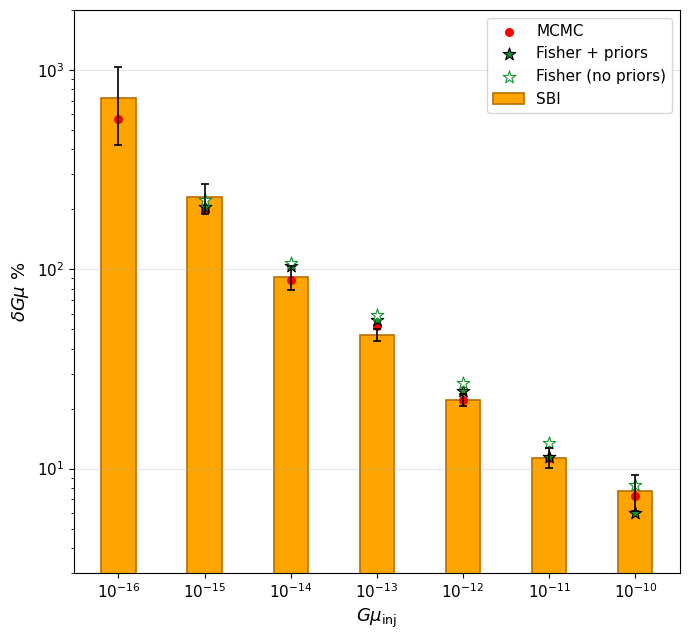

In [7]:
fig4 = P.plot_paper_fig4(S("sbi_fg_summary_with_errors.npz"), mcmc=MCMC,
                         fisher={"Fisher + priors": S("fisher_priors_95_intervals.npz"),
                                 "Fisher (no priors)": S("fisher_95_intervals.npz")},
                         out=OUT / "fig4_validation.pdf")

## Extra figures (not in the paper)

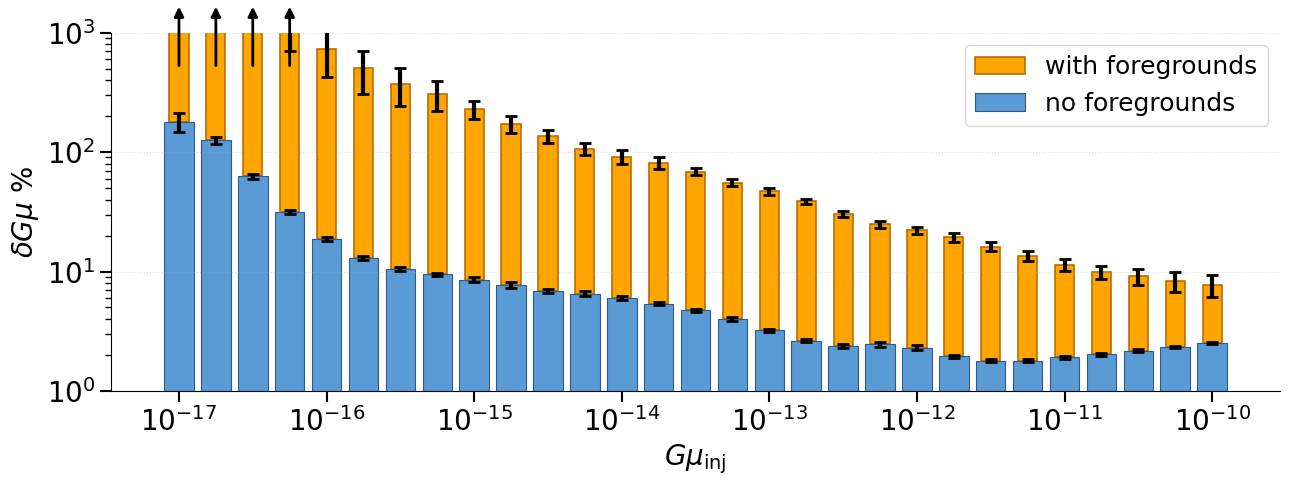

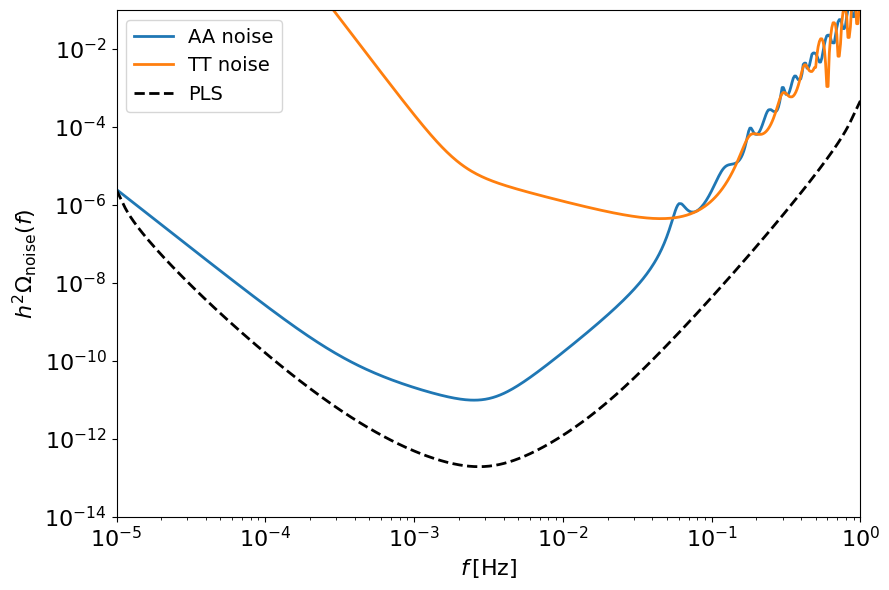

In [8]:
P.plot_fg_vs_nofg(S("sbi_fg_summary_with_errors.npz"), S("sbi_nofg_summary_with_errors.npz"),
                  out=OUT / "sbi_precision_fg_vs_nofg.pdf")
plot_noise_and_pls(out=OUT / "lisa_noise_pls_AA_TT.pdf");

## 5. Regenerating the inputs (slow — off by default)

* SBI precision scans: hours per case.  * Fisher: minutes.  * MCMC: hours per injection.

In [9]:
RUN_SCANS, RUN_FISHER, RUN_MCMC = False, False, False

if RUN_SCANS:
    for model, sign, name in (("full", 0, "sbi_fg"), ("full", -1, "sbi_lowfg"), ("full", 1, "sbi_highfg"),
                              ("nofg", 0, "sbi_nofg"), ("gbexb", 0, "sbi_gbexb")):
        scan.run_sbi_scan(model, posterior=load_post(model), fg_sign=sign, output_dir=RES, summary_name=name)
if RUN_FISHER:
    from gwbf_foregrounds import fisher
    fisher.run_fisher("full", output_dir=RES); fisher.run_fisher("nofg", output_dir=RES)
    fisher.run_fisher("full", output_dir=RES, with_priors=True)
if RUN_MCMC:
    for lg in (-16, -15, -14, -13, -12, -11, -10):
        ds = data.simulate("full", logGmu=lg, seed=42)
        mcmc.run_mcmc(ds, output_file=RES / f"mcmc_{data.tag_from_logGmu(lg)}.npz")